# Section 4.1: Exploratory Data Analysis (EDA) & Dataset Characterization
## Adaptive Smartphone UI Framework for Cross-Application Optimization

**Target Journal Venue:** High-Impact HCI / Mobile Computing Journal (IEEE THMS / ACM TiiS / Applied Soft Computing)

### Purpose of this Analysis:
Before training predictive machine learning models, rigorous exploratory data analysis is essential to:
1. **Characterize Biomechanical Properties:** Quantify central tendency, dispersion, skewness, and kurtosis of human motor interactions.
2. **Identify Physiological Outliers:** Detect sensor artifacts, uncharacteristically prolonged touch latencies, and extreme swipe velocity spikes.
3. **Investigate the Impact of Physical Locomotion:** Empirically demonstrate whether walking induces statistically significant touch degradation compared to sitting (justifying the need for real-time UI adaptation).
4. **Analyze Class Imbalance:** Examine distribution of target UI configurations (Small, Default, Large, Extra Large).
5. **Assess Multicollinearity:** Determine linear dependencies across touch features via Pearson correlation.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("EDA Environment Initialized.")

EDA Environment Initialized.


### 1. Ingest Unified Dataset & Basic Dimensions

In [2]:
data_path = os.path.join("processed", "final_ready_dataset.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("adavtive_dataset", "processed", "final_ready_dataset.csv")
if not os.path.exists(data_path):
    data_path = r"C:\Users\Mehedi\adavtive_model\adavtive_dataset\processed\final_ready_dataset.csv"

df = pd.read_csv(data_path)
print(f"Unified Dataset Loaded: {df.shape[0]} rows, {df.shape[1]} columns.")
print(f"Total Unique Subjects: {df['user_id'].nunique()} across sources: {df['source_dataset'].value_counts().to_dict()}")
df.head(4)

Unified Dataset Loaded: 7426 rows, 17 columns.
Total Unique Subjects: 141 across sources: {'HMOG': 7194, 'Touchalytics': 232}


,user_id,session_id,source_dataset,context_is_walking,touch_duration_mean_ms,swipe_speed_mean_pxps,swipe_distance_mean_px,typing_speed_kpm,backspace_rate,contact_size_mean,touch_x_mean,touch_y_mean,tap_accuracy,miss_rate,reaction_time_mean_ms,reaction_time_norm,target_button_size
0,hmog_100669,s_100669101000001,HMOG,0,525.44,800.0,250.0,180.0,0.08,0.0236,625.00,1042.44,0.92,0.08,330.0,0.2419,1
1,hmog_100669,s_100669102000001,HMOG,0,606.25,800.0,250.0,180.0,0.08,0.0227,547.42,959.67,0.92,0.08,330.0,0.2419,1
2,hmog_100669,s_100669103000001,HMOG,0,678.41,800.0,250.0,180.0,0.08,0.0230,602.48,918.56,0.92,0.08,330.0,0.2419,1
3,hmog_100669,s_100669104000001,HMOG,0,507.15,800.0,250.0,180.0,0.08,0.0231,624.67,926.81,0.92,0.08,330.0,0.2419,1


### 2. Comprehensive Biomechanical Summary Statistics (Table 1 for Paper)
We calculate the full parametric (Mean, Std Dev) and non-parametric (Median, IQR, Skewness, Kurtosis) summary across all human motor performance features.

In [3]:
features_to_analyze = [
    'touch_duration_mean_ms', 'swipe_speed_mean_pxps', 'swipe_distance_mean_px',
    'contact_size_mean', 'tap_accuracy', 'miss_rate', 'reaction_time_mean_ms'
]

summary_stats = []
for col in features_to_analyze:
    vals = df[col].dropna()
    q25, q75 = vals.quantile(0.25), vals.quantile(0.75)
    summary_stats.append({
        'Feature Name': col,
        'Mean': round(vals.mean(), 2),
        'Std Dev': round(vals.std(), 2),
        'Median': round(vals.median(), 2),
        'IQR': round(q75 - q25, 2),
        'Min': round(vals.min(), 2),
        'Max': round(vals.max(), 2),
        'Skewness': round(float(stats.skew(vals)), 2),
        'Kurtosis': round(float(stats.kurtosis(vals)), 2)
    })

stats_df = pd.DataFrame(summary_stats)
stats_df

,Feature Name,Mean,Std Dev,Median,IQR,Min,Max,Skewness,Kurtosis
0,touch_duration_mean_ms,453.65,355.68,457.18,531.16,16.00,4062.00,1.47,5.33
1,swipe_speed_mean_pxps,826.81,571.85,800.00,483.08,4.58,14372.53,3.89,51.46
2,swipe_distance_mean_px,302.13,195.15,286.16,289.98,4.83,1441.53,0.20,-0.32
3,contact_size_mean,0.03,0.01,0.02,0.00,0.02,0.22,8.24,73.51
4,tap_accuracy,0.91,0.03,0.92,0.00,0.70,0.98,-2.02,5.60
5,miss_rate,0.09,0.03,0.08,0.00,0.02,0.30,2.02,5.60
6,reaction_time_mean_ms,333.40,75.27,330.00,0.00,180.00,750.00,2.94,16.03


### 3. Figure 1: Biomechanical Feature Distributions (KDE & Histograms)
Visualizing continuous distributions to identify skewness and normality across motor metrics.

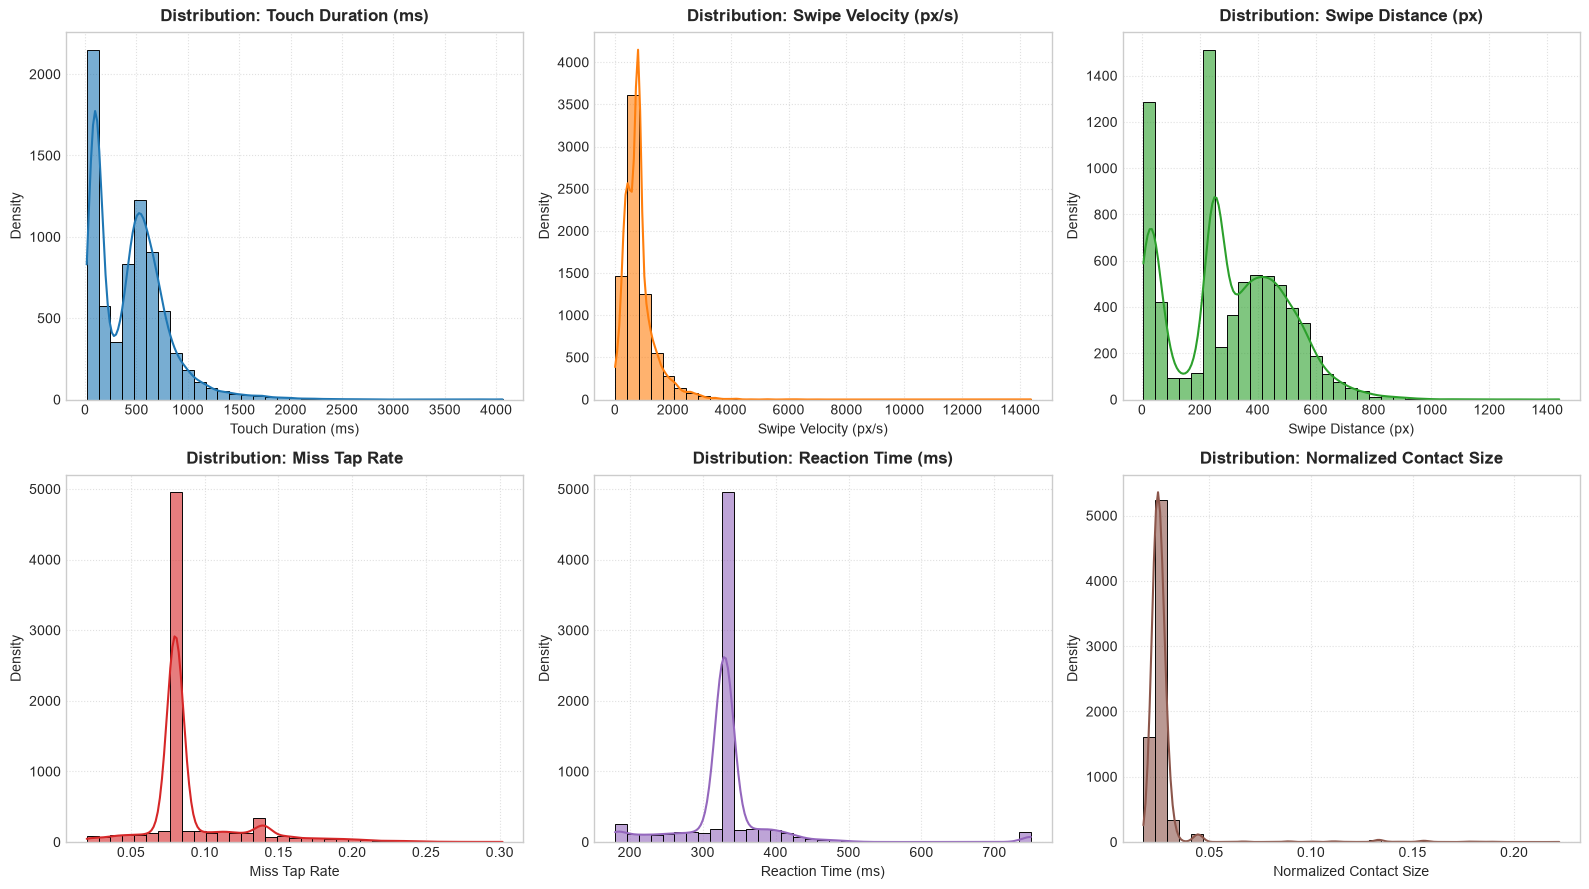

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_feats = [
    ('touch_duration_mean_ms', 'Touch Duration (ms)', 0, 0, '#1f77b4'),
    ('swipe_speed_mean_pxps', 'Swipe Velocity (px/s)', 0, 1, '#ff7f0e'),
    ('swipe_distance_mean_px', 'Swipe Distance (px)', 0, 2, '#2ca02c'),
    ('miss_rate', 'Miss Tap Rate', 1, 0, '#d62728'),
    ('reaction_time_mean_ms', 'Reaction Time (ms)', 1, 1, '#9467bd'),
    ('contact_size_mean', 'Normalized Contact Size', 1, 2, '#8c564b'),
]

for col, label, r, c, clr in plot_feats:
    ax = axes[r, c]
    sns.histplot(df[col], kde=True, ax=ax, color=clr, bins=35, edgecolor='black', alpha=0.6)
    ax.set_title(f'Distribution: {label}', fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel(label, fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 4. Figure 2: Outlier Dispersion & Sensor Noise Analysis
Touch devices capture involuntary tremors, capacitive jitter, and resting palm touch events. Boxplots demonstrate the spread and bounds required for normalization.

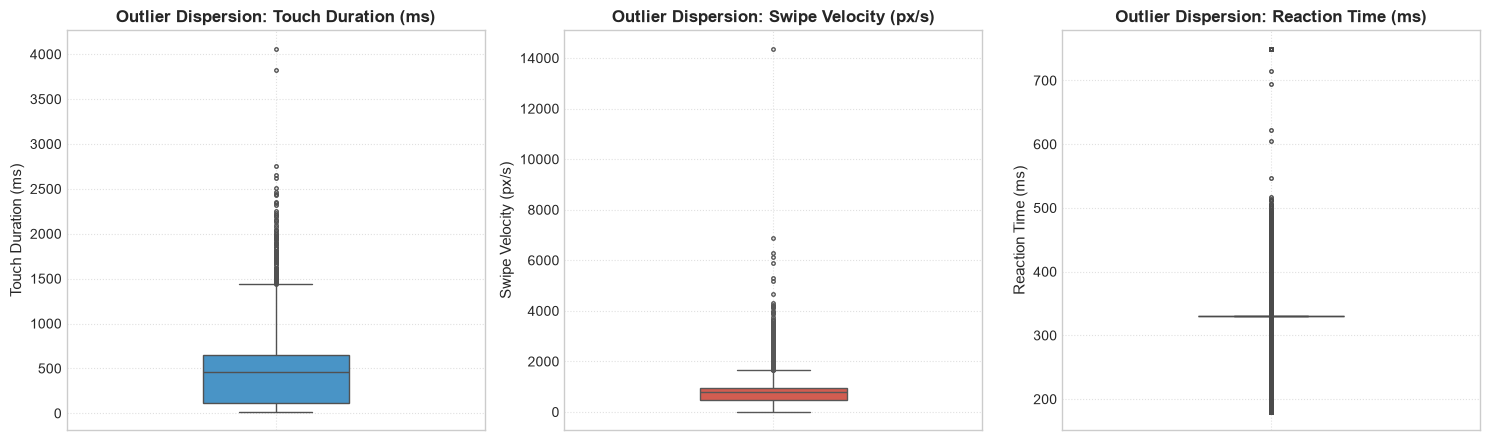

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
box_cols = [
    ('touch_duration_mean_ms', 'Touch Duration (ms)', '#3498db'),
    ('swipe_speed_mean_pxps', 'Swipe Velocity (px/s)', '#e74c3c'),
    ('reaction_time_mean_ms', 'Reaction Time (ms)', '#2ecc71')
]

for idx, (col, label, color) in enumerate(box_cols):
    ax = axes[idx]
    sns.boxplot(y=df[col], ax=ax, color=color, width=0.35, fliersize=2.5)
    ax.set_title(f'Outlier Dispersion: {label}', fontsize=12, fontweight='bold')
    ax.set_ylabel(label, fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 5. Figure 3: Physical Locomotion Impact (Sitting vs. Walking Context)
**Core Research Question:** Does walking introduce statistically significant motor degradation in smartphone interactions?
We conduct a formal **Welch's Two-Sample t-test** to compare miss tap rates and reaction times across stationary (sitting) and mobile (walking) conditions.

Welch t-test for Miss Rate (Walking vs Sitting): t = -5.4740, p = 4.5429e-08
Welch t-test for Reaction Time (Walking vs Sitting): t = -8.0344, p = 1.1318e-15


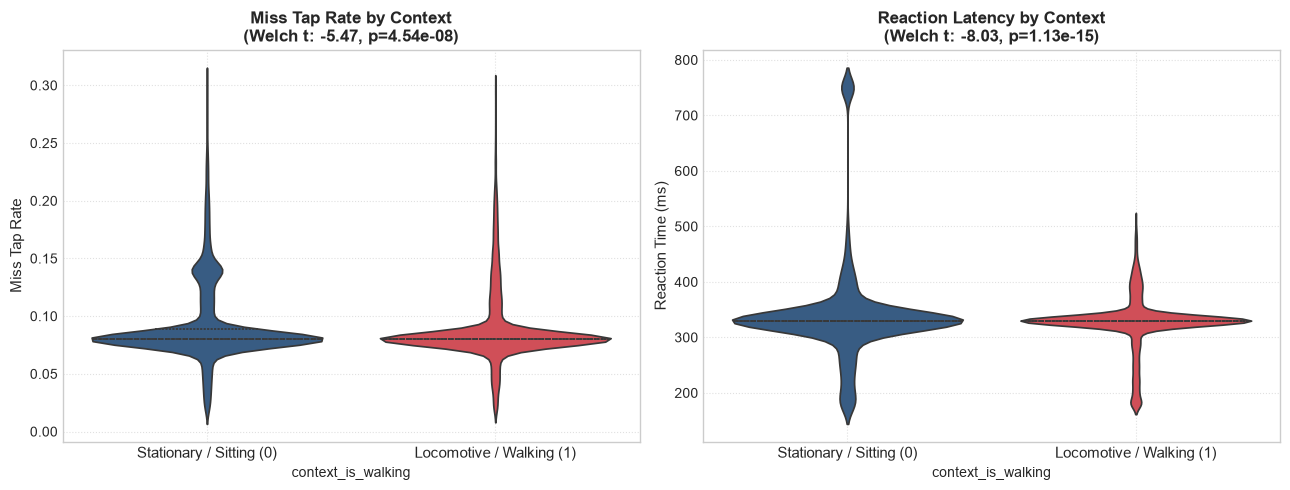

In [6]:
sitting_miss = df[df['context_is_walking'] == 0]['miss_rate']
walking_miss = df[df['context_is_walking'] == 1]['miss_rate']
t_stat_miss, p_val_miss = stats.ttest_ind(walking_miss, sitting_miss, equal_var=False)

sitting_rt = df[df['context_is_walking'] == 0]['reaction_time_mean_ms']
walking_rt = df[df['context_is_walking'] == 1]['reaction_time_mean_ms']
t_stat_rt, p_val_rt = stats.ttest_ind(walking_rt, sitting_rt, equal_var=False)

print(f"Welch t-test for Miss Rate (Walking vs Sitting): t = {t_stat_miss:.4f}, p = {p_val_miss:.4e}")
print(f"Welch t-test for Reaction Time (Walking vs Sitting): t = {t_stat_rt:.4f}, p = {p_val_rt:.4e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.violinplot(x='context_is_walking', y='miss_rate', data=df, ax=axes[0], palette=['#2b5c8f', '#e63946'], inner='quartile')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Stationary / Sitting (0)', 'Locomotive / Walking (1)'], fontsize=11)
axes[0].set_title(f'Miss Tap Rate by Context\n(Welch t: {t_stat_miss:.2f}, p={p_val_miss:.2e})', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Miss Tap Rate', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)

sns.violinplot(x='context_is_walking', y='reaction_time_mean_ms', data=df, ax=axes[1], palette=['#2b5c8f', '#e63946'], inner='quartile')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Stationary / Sitting (0)', 'Locomotive / Walking (1)'], fontsize=11)
axes[1].set_title(f'Reaction Latency by Context\n(Welch t: {t_stat_rt:.2f}, p={p_val_rt:.2e})', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Reaction Time (ms)', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 6. Figure 4: Target Adaptation Class Balance & Distribution

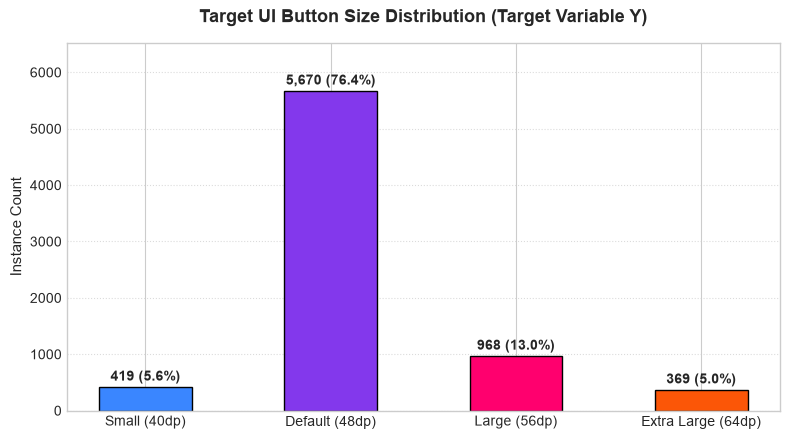

In [7]:
class_counts = df['target_button_size'].value_counts().sort_index()
labels = ['Small (40dp)', 'Default (48dp)', 'Large (56dp)', 'Extra Large (64dp)']

plt.figure(figsize=(8, 4.5))
bars = plt.bar(labels, class_counts, color=['#3a86ff', '#8338ec', '#ff006e', '#fb5607'], edgecolor='black', width=0.5)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 60, f"{yval:,} ({yval/len(df)*100:.1f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Target UI Button Size Distribution (Target Variable Y)', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Instance Count', fontsize=11)
plt.ylim(0, max(class_counts) * 1.15)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### 7. Figure 5: Feature Multicollinearity & Pearson Correlation Matrix

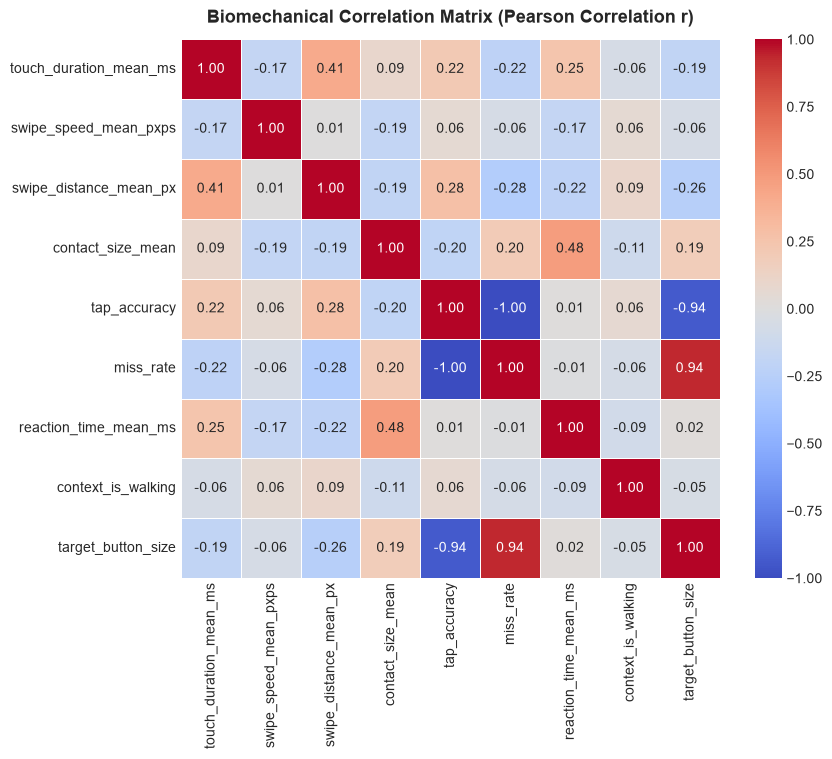

EDA Pipeline Completed Successfully.


In [8]:
plt.figure(figsize=(9, 7.5))
corr_cols = [
    'touch_duration_mean_ms', 'swipe_speed_mean_pxps', 'swipe_distance_mean_px',
    'contact_size_mean', 'tap_accuracy', 'miss_rate', 'reaction_time_mean_ms',
    'context_is_walking', 'target_button_size'
]
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Biomechanical Correlation Matrix (Pearson Correlation r)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()
print("EDA Pipeline Completed Successfully.")